In [322]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from sklearn.ensemble import IsolationForest
from sklearn.metrics import precision_score, recall_score, f1_score, confusion_matrix
import pickle

In [260]:
data = pd.read_csv('train.csv')
data['Timestamp'] = pd.to_datetime(data['Timestamp'])
data = data.sort_values(by='Timestamp').reset_index(drop=True)
data.head()

,Timestamp,Oil_Pressure_Bar,Bearing_Temp_C,Vibration_mm_s,RPM,Active_Power_MW,Water_Flow_m3_h
0,2026-10-26 22:00:00,4.2,66.0,1.7,3000.5,151.0,1200.6
1,2026-10-26 22:01:00,4.2,65.5,1.9,2999.3,150.5,1199.3
2,2026-10-26 22:02:00,4.2,66.0,1.9,3003.2,150.3,1203.4
3,2026-10-26 22:03:00,4.2,65.8,1.8,2999.9,151.0,1202.5
4,2026-10-26 22:04:00,4.1,65.1,2.0,2999.1,149.9,1200.9


In [261]:
data.describe()

,Timestamp,Oil_Pressure_Bar,Bearing_Temp_C,Vibration_mm_s,RPM,Active_Power_MW,Water_Flow_m3_h
count,1440,1440.000000,1440.000000,1440.000000,1440.000000,1440.000000,1440.000000
mean,2026-10-27 09:59:30.000000256,4.198194,65.619722,1.857986,2999.825347,150.544375,1200.368819
min,2026-10-26 22:00:00,3.500000,64.300000,1.500000,2956.700000,149.200000,1192.700000
25%,2026-10-27 03:59:45,4.200000,65.300000,1.800000,2998.800000,150.200000,1198.600000
50%,2026-10-27 09:59:30,4.200000,65.500000,1.900000,3000.000000,150.500000,1200.300000
75%,2026-10-27 15:59:15,4.200000,65.800000,1.900000,3001.200000,150.800000,1201.700000
max,2026-10-27 21:59:00,4.300000,76.600000,3.900000,3006.400000,155.300000,1234.100000
std,NaN,0.059970,0.962710,0.184282,3.188878,0.603899,3.378587


In [262]:
print('Всего строк: ', len(data), ', пропуски в данных не обнаружены, интервал по времени "1 минута"', sep='')
print('\nКоличество пропусков:')
print(data.isna().sum())
print('\nШаг по времени:')
print(data['Timestamp'][1] - data['Timestamp'][0])
print('Дубликатов времени:', data['Timestamp'].duplicated().sum())

Всего строк: 1440, пропуски в данных не обнаружены, интервал по времени "1 минута"

Количество пропусков:
Timestamp           0
Oil_Pressure_Bar    0
Bearing_Temp_C      0
Vibration_mm_s      0
RPM                 0
Active_Power_MW     0
Water_Flow_m3_h     0
dtype: int64

Шаг по времени:
0 days 00:01:00
Дубликатов времени: 0


In [263]:
features = data.drop(columns='Timestamp').columns.to_list()
features

['Oil_Pressure_Bar',
 'Bearing_Temp_C',
 'Vibration_mm_s',
 'RPM',
 'Active_Power_MW',
 'Water_Flow_m3_h']

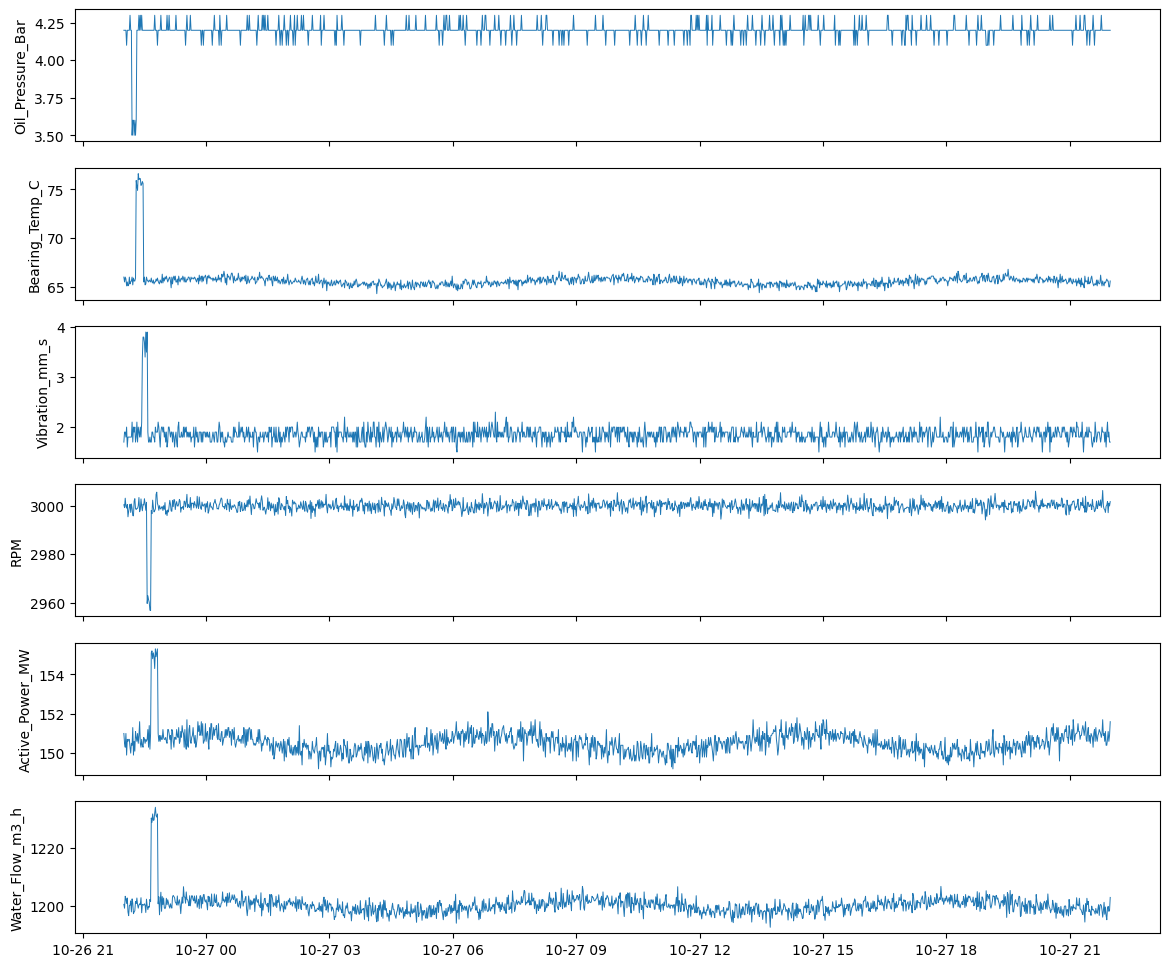

In [264]:
fig, axes = plt.subplots(len(features), 1, figsize=(14, 12), sharex=True)

for ax, f in zip(axes, features):
    ax.plot(data['Timestamp'], data[f], lw=0.7)
    ax.set_ylabel(f)

In [265]:
intervals = []
for f in features:
    tmp_lst = []
    distance = (data[f] - data[f].median()).abs()
    bad = data[distance > 5 * data[f].std()].reset_index(drop=True)
    for row in bad['Timestamp']:
        tmp_lst.append(row)

    if len(tmp_lst) == 0:                      
        continue

    start = tmp_lst[0]
    for i in range(1, len(tmp_lst)):
        if tmp_lst[i] - tmp_lst[i - 1] > pd.Timedelta(minutes=3):
            intervals.append((start, tmp_lst[i - 1]))
            start = tmp_lst[i]
    intervals.append((start, tmp_lst[-1]))

for s, e in intervals:
    print(s, '-', e)
print('Интервалов:', len(intervals))

2026-10-26 22:12:00 - 2026-10-26 22:18:00
2026-10-26 22:18:00 - 2026-10-26 22:28:00
2026-10-26 22:27:00 - 2026-10-26 22:34:00
2026-10-26 22:34:00 - 2026-10-26 22:39:00
2026-10-26 22:40:00 - 2026-10-26 22:49:00
2026-10-26 22:40:00 - 2026-10-26 22:49:00
Интервалов: 6


In [266]:
after = data[data['Timestamp'] > '2026-10-26 22:50']
for f in features:
    dist = (after[f] - after[f].median()).abs() / after[f].std()
    print(f, [(k, int((dist > k).sum())) for k in (3, 4, 5)])

Oil_Pressure_Bar [(3, 0), (4, 0), (5, 0)]
Bearing_Temp_C [(3, 2), (4, 0), (5, 0)]
Vibration_mm_s [(3, 14), (4, 0), (5, 0)]
RPM [(3, 6), (4, 0), (5, 0)]
Active_Power_MW [(3, 1), (4, 0), (5, 0)]
Water_Flow_m3_h [(3, 1), (4, 0), (5, 0)]


In [267]:
data['label'] = 0

for start, end in intervals:
    data.loc[data['Timestamp'].between(start, end), 'label'] = 1

print('Аномальных минут:', data['label'].sum(), 'из', len(data))

Аномальных минут: 38 из 1440


In [268]:
T_start = data['Timestamp'].min()
T_end = data['Timestamp'].max()

t_test_end = T_start + pd.Timedelta(hours=2)
t_val_start = T_start + pd.Timedelta(hours=17)

data['part'] = 'train'
data.loc[data['Timestamp'] < t_test_end, 'part'] = 'test'
data.loc[data['Timestamp'] >= t_val_start, 'part'] = 'val'

near_anomaly = data['label'].rolling(7, min_periods=1, center=True).max().astype(bool)
train_mask = (data['part'] == 'train') & ~near_anomaly
val_mask = data['part'] == 'val'
test_mask = data['part'] == 'test'

print(data['part'].value_counts())
print(data.groupby('part')['label'].sum())
print('Строк для обучения:', train_mask.sum())

part
train    900
val      420
test     120
Name: count, dtype: int64
part
test     38
train     0
val       0
Name: label, dtype: int64
Строк для обучения: 900


In [269]:
mu = data.loc[train_mask, features].mean()
sd = data.loc[train_mask, features].std()
print(pd.DataFrame({'mean': mu, 'std': sd}))

                         mean       std
Oil_Pressure_Bar     4.201222  0.040418
Bearing_Temp_C      65.498111  0.378668
Vibration_mm_s       1.850889  0.124476
RPM               2999.977667  1.823234
Active_Power_MW    150.489333  0.482252
Water_Flow_m3_h   1199.890222  2.256636


In [270]:
Z = ((data[features] - mu) / sd).abs()

In [271]:
rows = []
for K in [3, 4, 5, 6, 8, 10]:
    pred = (Z > K).any(axis=1)
    rows.append({'K': K,
                 'ложных тревог в train': int(pred[train_mask].sum()),
                 'ложных тревог в val': int(pred[val_mask].sum())})
res_thr = pd.DataFrame(rows)
res_thr

,K,ложных тревог в train,ложных тревог в val
0,3,9,5
1,4,0,0
2,5,0,0
3,6,0,0
4,8,0,0
5,10,0,0


In [272]:
ok = res_thr[res_thr['ложных тревог в val'] <= 4]
K_best = ok['K'].min()
K_best

np.int64(4)

In [273]:
data['thr_anomaly'] = (Z > K_best).any(axis=1).astype(int)

In [274]:
viol = Z > K_best
data['thr_sensors'] = viol.apply(lambda r: ', '.join(r.index[r]), axis=1)

In [275]:
data

,Timestamp,Oil_Pressure_Bar,Bearing_Temp_C,Vibration_mm_s,RPM,Active_Power_MW,Water_Flow_m3_h,label,part,thr_anomaly,thr_sensors
0,2026-10-26 22:00:00,4.2,66.0,1.7,3000.5,151.0,1200.6,0,test,0,
1,2026-10-26 22:01:00,4.2,65.5,1.9,2999.3,150.5,1199.3,0,test,0,
2,2026-10-26 22:02:00,4.2,66.0,1.9,3003.2,150.3,1203.4,0,test,0,
3,2026-10-26 22:03:00,4.2,65.8,1.8,2999.9,151.0,1202.5,0,test,0,
4,2026-10-26 22:04:00,4.1,65.1,2.0,2999.1,149.9,1200.9,0,test,0,
...,...,...,...,...,...,...,...,...,...,...,...
1435,2026-10-27 21:55:00,4.2,65.6,2.1,3001.8,150.7,1199.3,0,val,0,
1436,2026-10-27 21:56:00,4.2,65.6,1.8,2997.2,151.1,1199.9,0,val,0,
1437,2026-10-27 21:57:00,4.2,65.0,1.9,3001.2,150.6,1198.2,0,val,0,
1438,2026-10-27 21:58:00,4.2,65.0,1.7,3000.0,150.9,1198.5,0,val,0,


In [289]:
X_train = data.loc[train_mask, features]
X_val = data.loc[val_mask, features]

contaminations = [0.001, 0.002, 0.005, 0.01, 0.02]
results = []

for cont in contaminations:
    isolation_forest = IsolationForest(n_estimators=300, contamination=cont, random_state=17)
    isolation_forest.fit(X_train)
    val = isolation_forest.predict(X_val)
    false_anomaly = (val == -1).sum()
    results.append((cont, false_anomaly))
    print('contamination =', cont, 'ложных срабатываний:', false_anomaly)

good = [cont for cont, false_anomaly in results if false_anomaly <= 1]
cont_best = max(good)

print('\nВыбрано contamination =', cont_best)

contamination = 0.001 ложных срабатываний: 0
contamination = 0.002 ложных срабатываний: 0
contamination = 0.005 ложных срабатываний: 1
contamination = 0.01 ложных срабатываний: 3
contamination = 0.02 ложных срабатываний: 7

Выбрано contamination = 0.005


In [293]:
isolation_forest = IsolationForest(n_estimators=300, contamination=cont_best, random_state=17)
isolation_forest.fit(X_train)

data['score'] = isolation_forest.decision_function(data[features])
data['is_anomaly'] = (isolation_forest.predict(data[features]) == -1).astype(int)

In [295]:
print(data.groupby('label')['score'].mean())
print(data.groupby('part')['is_anomaly'].sum())

label
0    0.156613
1    0.047280
Name: score, dtype: float64
part
test     8
train    5
val      1
Name: is_anomaly, dtype: int64


In [312]:
X_test = data.loc[test_mask, features]
y_test = data.loc[test_mask, 'label']

y_pred = (isolation_forest.predict(X_test) == -1).astype(int)

print('precision:', round(precision_score(y_test, y_pred), 3))
print('recall:', round(recall_score(y_test, y_pred), 3))
print('F1_score', round(f1_score(y_test, y_pred), 3))
print(confusion_matrix(y_test, y_pred))

precision: 0.875
recall: 0.184
F1_score 0.304
[[81  1]
 [31  7]]


In [314]:
y_pred_thr = data.loc[test_mask, 'thr_anomaly']

print('precision:', round(precision_score(y_test, y_pred_thr), 3))
print('recall:', round(recall_score(y_test, y_pred_thr), 3))
print('F1_score', round(f1_score(y_test, y_pred_thr), 3))
print(confusion_matrix(y_test, y_pred_thr))

precision: 1.0
recall: 1.0
F1_score 1.0
[[82  0]
 [ 0 38]]


In [316]:
def make_episodes(mask, gap=2, min_len=3):
    times = data.loc[mask, 'Timestamp'].tolist()
    if not times:
        return []
    
    episodes = []
    start = prev = times[0]
    count = 1
    
    for t in times[1:]:
        if t - prev > pd.Timedelta(minutes=gap + 1):
            if count >= min_len:
                episodes.append((start, prev))
            start, count = t, 0
        prev = t
        count += 1
    
    if count >= min_len:
        episodes.append((start, prev))

    return episodes


eps_thr = make_episodes(data['thr_anomaly'] == 1)
eps_if = make_episodes(data['is_anomaly'] == 1)
print('Пороговый:', eps_thr)
print('Isolation Forest:', eps_if)

Пороговый: [(Timestamp('2026-10-26 22:12:00'), Timestamp('2026-10-26 22:49:00'))]
Isolation Forest: [(Timestamp('2026-10-26 22:45:00'), Timestamp('2026-10-26 22:49:00'))]


In [317]:
for s, e in eps_if:
    zz = Z[data['Timestamp'].between(s, e)].max().sort_values(ascending=False)
    print(s, '-', e, '|', dict(zz.head(3).round(1)))

2026-10-26 22:45:00 - 2026-10-26 22:49:00 | {'Water_Flow_m3_h': np.float64(15.2), 'Active_Power_MW': np.float64(10.0), 'RPM': np.float64(3.1)}


In [318]:
true_start = min(s for s, e in intervals)
true_end = max(e for s, e in intervals)

def check(name, episodes):
    found = [(s, e) for s, e in episodes if s <= true_end and e >= true_start]
    false_eps = [(s, e) for s, e in episodes if not (s <= true_end and e >= true_start)]
    print(name)
    if found:
        s = min(x[0] for x in found)
        e = max(x[1] for x in found)
        print('  инцидент найден, сдвиг начала:', (s - true_start).total_seconds() / 60,
              'мин, сдвиг конца:', (e - true_end).total_seconds() / 60, 'мин')
    else:
        print('  инцидент НЕ найден')
    print('  ложных эпизодов:', len(false_eps), false_eps)

check('Пороговый', eps_thr)
check('Isolation Forest', eps_if)

Пороговый
  инцидент найден, сдвиг начала: 0.0 мин, сдвиг конца: 0.0 мин
  ложных эпизодов: 0 []
Isolation Forest
  инцидент найден, сдвиг начала: 33.0 мин, сдвиг конца: 0.0 мин
  ложных эпизодов: 0 []


In [319]:
for f in features:
    first = data.loc[test_mask & (Z[f] > K_best), 'Timestamp'].min()
    print(f, '- первое отклонение:', first)

Oil_Pressure_Bar - первое отклонение: 2026-10-26 22:12:00
Bearing_Temp_C - первое отклонение: 2026-10-26 22:18:00
Vibration_mm_s - первое отклонение: 2026-10-26 22:27:00
RPM - первое отклонение: 2026-10-26 22:34:00
Active_Power_MW - первое отклонение: 2026-10-26 22:40:00
Water_Flow_m3_h - первое отклонение: 2026-10-26 22:40:00


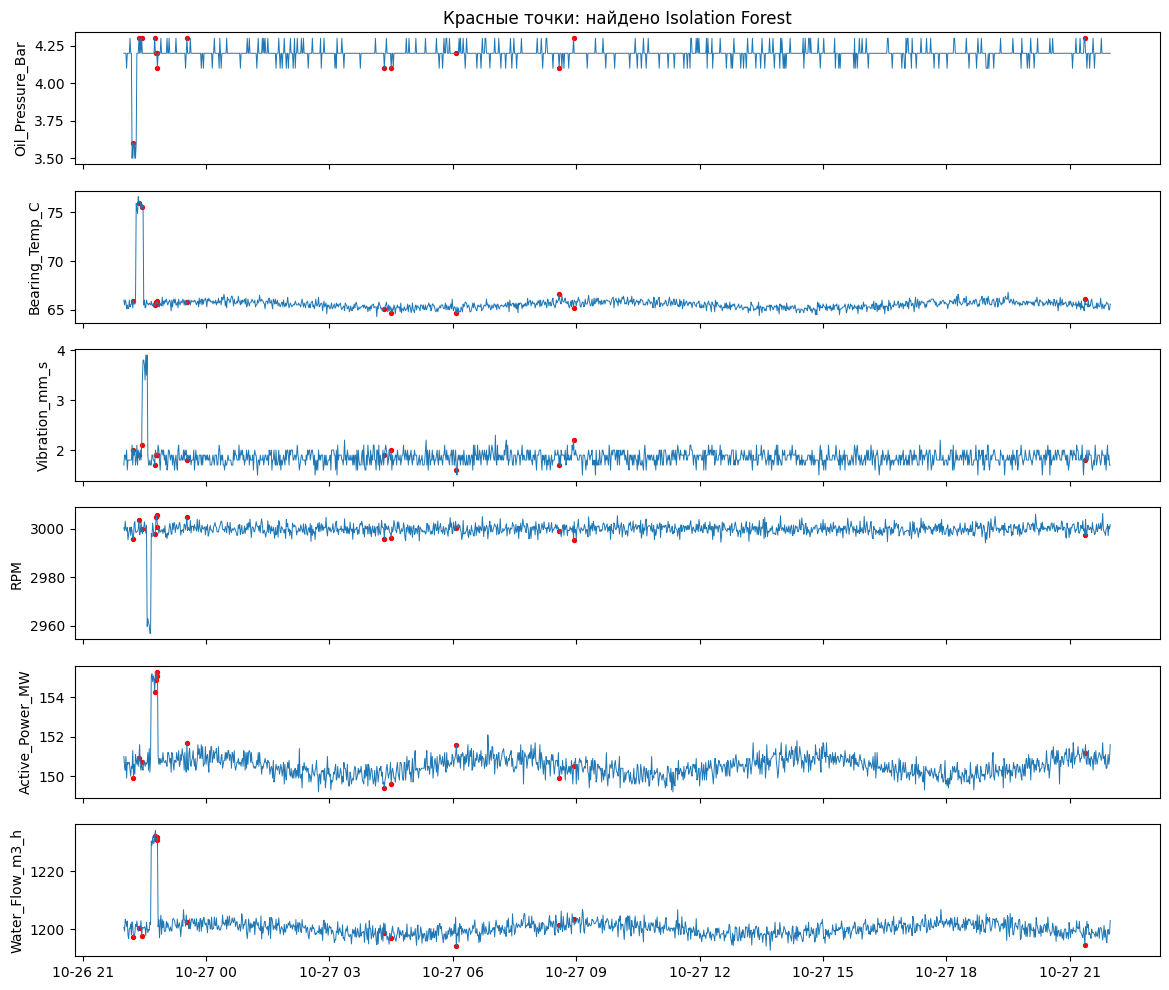

In [320]:
fig, axes = plt.subplots(len(features), 1, figsize=(14, 12), sharex=True)
bad = data[data['is_anomaly'] == 1]

for ax, f in zip(axes, features):
    ax.plot(data['Timestamp'], data[f], lw=0.7)
    ax.scatter(bad['Timestamp'], bad[f], c='red', s=8)
    ax.set_ylabel(f)
axes[0].set_title('Красные точки: найдено Isolation Forest')
plt.show()

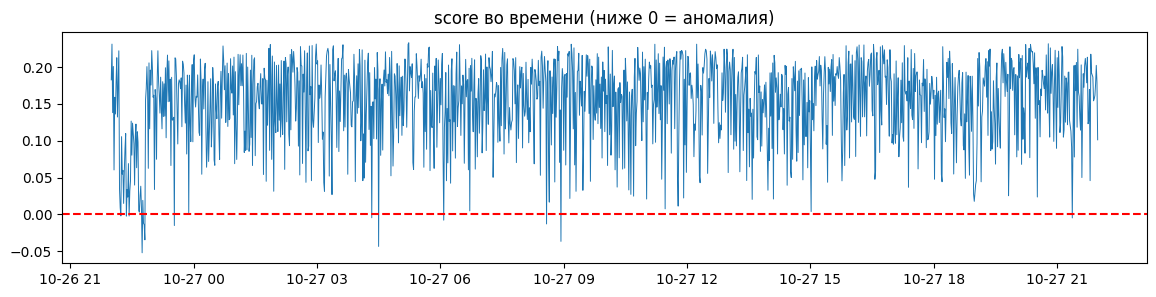

In [321]:
plt.figure(figsize=(14, 3))
plt.plot(data['Timestamp'], data['score'], lw=0.7)
plt.axhline(0, color='red', ls='--')
plt.title('score во времени (ниже 0 = аномалия)')
plt.show()

In [323]:
with open('model.pkl', 'wb') as f:
    pickle.dump(isolation_forest, f)